# 2019-2026 Precipitation: Rain Gauges, Hydrograph, and Thiessen Map

This notebook reads all rain gauge from 2019-2026 taken from Toronto's OpenData, plots the selected gauge's hourly precipitation and cumulative hydrograph, and displays a labelled, interactive Thiessen map of daily rainfall totals. Use the **Date** calendar picker to view each day's totals by gauge.

No watershed boundary was provided, so Thiessen polygons are clipped to the convex hull of the gauge network. The method assigns each area the observation from its nearest gauge; it does not create a smooth rainfall surface or calculate an area-weighted catchment average. The rainfall will be measured in mm.

In [1]:
from pathlib import Path
from html import escape

import folium
import geopandas as gpd
import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from branca.colormap import linear, LinearColormap
from folium.features import DivIcon, GeoJsonTooltip
from IPython.display import display, HTML
from scipy.spatial import Voronoi
from shapely.geometry import Polygon
import os

%matplotlib inline

# Change these settings to select a gauge or focus the hydrograph on an event.
selected_gauge = "RG_056"
event_start = None  # Example: "2026-10-19 00:00"
event_end = None    # Example: "2026-10-20 00:00"

## Load and validate the rain gauge data
* Loads values from CSVs
* Removes missing values, duplicate rows, duplicate dates, and duplicate rain gauge observations

In [2]:
precipitation_2026 = pd.read_csv("precipitation-data-2026.csv")
precipitation_2026["date"] = pd.to_datetime(precipitation_2026["date"])
precipitation_2026["rainfall"] = pd.to_numeric(precipitation_2026["rainfall"])

In [3]:
folder_path=os.listdir()

# Filter the list to only keep files that end with '.csv'
csv_files = [file for file in folder_path if file.endswith('.csv')]

# Concatenate all annual rain data into one dataframe.
precipitation = pd.concat((pd.read_csv(file) for file in csv_files), ignore_index=True)

# Convert date column to date time format.
precipitation["date"] = pd.to_datetime(precipitation["date"])
precipitation["rainfall"]=pd.to_numeric(precipitation["rainfall"])

# Remove rows with missing or invalid values in essential columns
precipitation = precipitation.dropna(
    subset=["date", "name", "longitude", "latitude", "rainfall"]
).copy()

# Remove rows with invalid rainfall values
precipitation = precipitation[precipitation["rainfall"] >= 0]

# Remove exact duplicate rows
precipitation = precipitation.drop_duplicates()

# Remove duplicate date-gauge observations
# Keep the first observation for each date and gauge
precipitation = precipitation.drop_duplicates(
    subset=["date", "name"],
    keep="first"
)

# Creating a dataframe of unique rain gauges. Drop duplicates to get unique gauges, sort by name in ascending order, and set the index as the name.
gauges = (
    precipitation[["name", "longitude", "latitude"]]
    .drop_duplicates(subset="name")
    .sort_values("name")
    .reset_index(drop=True)
)

# Indexes the dataframe by the date.
rainfall_by_time = precipitation.pivot(index="date", columns="name", values="rainfall").reindex(columns=gauges["name"])

print(f"Available period: {rainfall_by_time.index.min()} to {rainfall_by_time.index.max()}")
print(f"Total Rainfall observations: {rainfall_by_time.size}")
print(f"0 mm Rainfall observations: {rainfall_by_time.isna().sum().sum():,}")


Available period: 2015-06-01 00:00:00 to 2026-10-20 09:40:00
Total Rainfall observations: 63472111
0 mm Rainfall observations: 8,647,091


In [4]:
precipitation.head()

,id,name,date,rainfall,longitude,latitude
0,7677,RG_001,2015-06-01 00:00:00,0.0,-79.478112,43.64768
1,7677,RG_001,2015-06-01 00:05:00,0.0,-79.478112,43.64768
2,7677,RG_001,2015-06-01 00:10:00,0.0,-79.478112,43.64768
3,7677,RG_001,2015-06-01 00:15:00,0.0,-79.478112,43.64768
4,7677,RG_001,2015-06-01 00:20:00,0.0,-79.478112,43.64768


## Splitting Dataframes (3 Season Rain Gauges and 4 Season Rain Gauges)

The city of Toronto has two sets of rain gauges:
1- 3 season rain gauges: they operate between Apr 1st to Oct 31st - We will assume all precipitation captured by them is rain
2- 4 season rain guages: they operate year round. They capture winter precipitation which we will assume is all snow

From city of Toronto Documentation


The tentative list of 3-season gauges is as follows: 
RG_001, RG_002, RG_003, RG_004, RG_006, RG_007, RG_012, RG_013, RG_014, RG_015, RG_020, RG_021
RG_022, RG_023, RG_024, RG_025, RG_027, RG_028, RG_030, RG_031, RG_033, RG_034, RG_035, RG_036, RG_037, RG_039, RG_040, RG_041, RG_042, RG_044, RG_045, RG_046, RG_047, RG_048, RG_049, RG_050, RG_051, RG_052, RG_053

The tentative list of 4-season gauges is as follows:
 RG_016, RG_017, RG_018, RG_019, RG_038


In [5]:
gauges

,name,longitude,latitude
0,RG_001,-79.478112,43.647680
1,RG_002,-79.443616,43.651196
2,RG_003,-79.405094,43.656616
3,RG_004,-79.402833,43.678343
4,RG_006,-79.375101,43.661265
5,RG_007,-79.331145,43.676720
6,RG_012,-79.581637,43.739217
7,RG_013,-79.571938,43.694917
8,RG_014,-79.541474,43.683430
9,RG_015,-79.528275,43.638065


In [6]:
rain_gauge_gpd=gpd.GeoDataFrame(gauges, geometry=gpd.points_from_xy(gauges.longitude, gauges.latitude), crs="32617").drop(columns=["longitude","latitude"])

In [7]:
# Load the Toronto neighbourhood boundaries using GeoPandas.
neighbourhoods = gpd.read_file("toronto_neighbourhoods.shp")

# Keep only the neighbourhood-name and geometry columns.
neighbourhoods = neighbourhoods[["FIELD_8", "geometry"]]

# Rename "FIELD_8" to "name".
neighbourhoods.columns = ["name", "geometry"]

# Remove the neighbourhood ID in parentheses from the end of each name.
# Hint: str.replace() with a regular expression may be useful.
neighbourhoods["name"] = neighbourhoods["name"].str.split("(").str[0].str.strip()
#splits the string after "(" and then takes the first index .str[0] then strips the trailing spaces

# Preview the cleaned GeoDataFrame
neighbourhoods.head()

,name,geometry
0,Wychwood,"POLYGON ((-79.43592 43.68015, -79.43492 43.680..."
1,Yonge-Eglinton,"POLYGON ((-79.41096 43.70408, -79.40962 43.704..."
2,Yonge-St.Clair,"POLYGON ((-79.39119 43.68108, -79.39141 43.680..."
3,York University Heights,"POLYGON ((-79.50529 43.75987, -79.50488 43.759..."
4,Yorkdale-Glen Park,"POLYGON ((-79.43969 43.70561, -79.44011 43.705..."


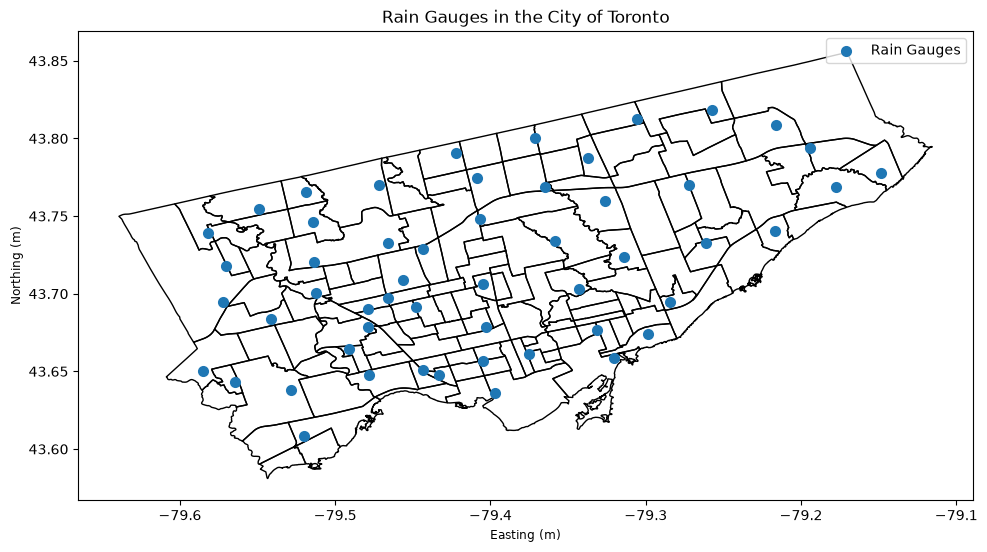

In [8]:
# Create one figure and axes for all spatial layers.
fig, ax = plt.subplots(figsize=(10, 8))

# Plot neighbourhood boundaries.
# Hint: use facecolor="none" so the other layers remain visible.
neighbourhoods.plot(ax=ax, linewidth=1, facecolor="none")

# Plot rain guages on the same axes.
rain_gauge_gpd.plot(ax=ax, linewidth=2, label="Rain Gauges")

# Add the required labels, title, and legend.
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_title("Rain Gauges in the City of Toronto")
ax.legend()
plt.tight_layout()
plt.show()

In [9]:
#4 Season Rain Guages
four_season_gauges=gauges[gauges["name"].isin(["RG_016", "RG_017", "RG_018", "RG_019", "RG_038"])].reset_index(drop=True)
four_season_gauges

,name,longitude,latitude
0,RG_016,-79.520366,43.608125
1,RG_017,-79.466028,43.697350
2,RG_018,-79.343284,43.703133
3,RG_019,-79.518838,43.765227
4,RG_038,-79.148405,43.777514


In [10]:
#3 season Rain Gauges
three_season_gauges = gauges[~gauges['name'].isin(four_season_gauges['name'])].reset_index(drop=True)
three_season_gauges

,name,longitude,latitude
0,RG_001,-79.478112,43.647680
1,RG_002,-79.443616,43.651196
2,RG_003,-79.405094,43.656616
3,RG_004,-79.402833,43.678343
4,RG_006,-79.375101,43.661265
5,RG_007,-79.331145,43.676720
6,RG_012,-79.581637,43.739217
7,RG_013,-79.571938,43.694917
8,RG_014,-79.541474,43.683430
9,RG_015,-79.528275,43.638065


In [11]:
print(precipitation.info())
precipitation

<class 'pandas.DataFrame'>
Index: 54825020 entries, 0 to 54935684
Data columns (total 6 columns):
 #   Column     Dtype         
---  ------     -----         
 0   id         int64         
 1   name       str           
 2   date       datetime64[us]
 3   rainfall   float64       
 4   longitude  float64       
 5   latitude   float64       
dtypes: datetime64[us](1), float64(3), int64(1), str(1)
memory usage: 3.2 GB
None


,id,name,date,rainfall,longitude,latitude
0,7677,RG_001,2015-06-01 00:00:00,0.0,-79.478112,43.647680
1,7677,RG_001,2015-06-01 00:05:00,0.0,-79.478112,43.647680
2,7677,RG_001,2015-06-01 00:10:00,0.0,-79.478112,43.647680
3,7677,RG_001,2015-06-01 00:15:00,0.0,-79.478112,43.647680
4,7677,RG_001,2015-06-01 00:20:00,0.0,-79.478112,43.647680
...,...,...,...,...,...,...
54935680,24936,RG_063,2026-10-20 09:15:00,0.0,-79.433216,43.647443
54935681,24936,RG_063,2026-10-20 09:20:00,0.0,-79.433216,43.647443
54935682,24936,RG_063,2026-10-20 09:25:00,0.0,-79.433216,43.647443
54935683,24936,RG_063,2026-10-20 09:30:00,0.0,-79.433216,43.647443


## Analyzing Data Patterns
Using aggregation to find the following information:
* Which rain gauges received the most rainfall during the 2019-2026 period? This could give an idea of which areas receive the most rain overall.
* Biggest rainfall within a day collected. Can potentially show which areas are most susceptible to flash floods.


#### Aggregating into Daily Rainfall

In [12]:
# Aggregate into daily rainfall for each rain gauge. Output the rain gauges that had the largest daily event.
daily_precipitation = precipitation.groupby(["name", "date"], observed=True)["rainfall"].sum(min_count=1).reset_index()
max_daily_precipitation=daily_precipitation.sort_values("rainfall",ascending=False)
max_daily_precipitation.head(20)

,name,date,rainfall
23206527,RG_027,2023-10-30 11:35:00,275.078
44917081,RG_049,2023-10-23 10:35:00,172.119
22064044,RG_025,2023-10-30 07:40:00,161.732
26553960,RG_031,2023-10-30 12:10:00,138.456
50275265,RG_056,2024-10-31 13:10:00,136.355
24193632,RG_028,2022-05-25 08:40:00,133.299
19454966,RG_023,2020-11-16 12:30:00,132.142
52698378,RG_059,2025-07-24 04:10:00,130.477
23290935,RG_027,2024-10-28 14:20:00,121.484
17134145,RG_021,2020-11-09 15:15:00,119.242


In [13]:
min_daily_precipitation=daily_precipitation.sort_values("rainfall",ascending=True)
min_daily_precipitation

,name,date,rainfall
54825016,RG_063,2026-10-20 09:20:00,0.000
17,RG_001,2015-06-01 01:25:00,0.000
18,RG_001,2015-06-01 01:30:00,0.000
19,RG_001,2015-06-01 01:35:00,0.000
20,RG_001,2015-06-01 01:40:00,0.000
...,...,...,...
50275265,RG_056,2024-10-31 13:10:00,136.355
26553960,RG_031,2023-10-30 12:10:00,138.456
22064044,RG_025,2023-10-30 07:40:00,161.732
44917081,RG_049,2023-10-23 10:35:00,172.119


## Splitting into two different dataframes
The city of Toronto indicated that their rain guages are either a 3-season guage or a 4-season guage. 

- Between Apr 1st and October 31st only the three season rain gauges are turned on 
- Between Nov 1st to March 31st all gauges are turned on

--> Split the dataframe into
- Between Apr 1st and Oct 31st --> all rain gauges --> rain 
- Between Nov 1st to Mar 31st --> only 4 season rain gauges --> Snow

In [14]:
#extract all records between april 1st and october 31st
all_rain_gauges_precipitation=daily_precipitation[(daily_precipitation["date"].dt.month >= 4)|(daily_precipitation["date"].dt.month >= 10)]
all_rain_gauges_precipitation

,name,date,rainfall
0,RG_001,2015-06-01 00:00:00,0.0
1,RG_001,2015-06-01 00:05:00,0.0
2,RG_001,2015-06-01 00:10:00,0.0
3,RG_001,2015-06-01 00:15:00,0.0
4,RG_001,2015-06-01 00:20:00,0.0
...,...,...,...
54825015,RG_063,2026-10-20 09:15:00,0.0
54825016,RG_063,2026-10-20 09:20:00,0.0
54825017,RG_063,2026-10-20 09:25:00,0.0
54825018,RG_063,2026-10-20 09:30:00,0.0


In [15]:
rainfall_by_time

name,RG_001,RG_002,RG_003,RG_004,RG_006,RG_007,RG_012,RG_013,RG_014,RG_015,...,RG_054,RG_055,RG_056,RG_057,RG_058,RG_059,RG_060,RG_061,RG_062,RG_063
date,,,,,,,,,,,,,,,,,,,,,
2015-06-01 00:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-06-01 00:05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-06-01 00:10:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-06-01 00:15:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-06-01 00:20:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-20 09:20:00,0.0,NaN,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.0,...,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-10-20 09:25:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-10-20 09:30:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [16]:
rainfall_by_time_all_gauges = rainfall_by_time[(rainfall_by_time.index.month >= 4) |(rainfall_by_time.index.month >= 10)]
rainfall_by_time_all_gauges

name,RG_001,RG_002,RG_003,RG_004,RG_006,RG_007,RG_012,RG_013,RG_014,RG_015,...,RG_054,RG_055,RG_056,RG_057,RG_058,RG_059,RG_060,RG_061,RG_062,RG_063
date,,,,,,,,,,,,,,,,,,,,,
2015-06-01 00:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-06-01 00:05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-06-01 00:10:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-06-01 00:15:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-06-01 00:20:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-20 09:20:00,0.0,NaN,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.0,...,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-10-20 09:25:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-10-20 09:30:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [17]:
#extract winter precipitation between Nov 1st and May 31st
winter_precipitation=daily_precipitation[~daily_precipitation['date'].isin(all_rain_gauges_precipitation['date'])]
winter_precipitation

,name,date,rainfall
61632,RG_001,2016-01-01 00:00:00,0.0
61633,RG_001,2016-01-01 00:05:00,0.0
61634,RG_001,2016-01-01 00:10:00,0.0
61635,RG_001,2016-01-01 00:15:00,0.0
61636,RG_001,2016-01-01 00:20:00,0.0
...,...,...,...
54767142,RG_063,2026-03-31 23:35:00,0.0
54767143,RG_063,2026-03-31 23:40:00,0.0
54767144,RG_063,2026-03-31 23:45:00,0.0
54767145,RG_063,2026-03-31 23:50:00,0.0


In [18]:
#winter months
rainfall_by_time_winter = rainfall_by_time[~rainfall_by_time.index.isin(rainfall_by_time_all_gauges.index)]
rainfall_by_time_winter

name,RG_001,RG_002,RG_003,RG_004,RG_006,RG_007,RG_012,RG_013,RG_014,RG_015,...,RG_054,RG_055,RG_056,RG_057,RG_058,RG_059,RG_060,RG_061,RG_062,RG_063
date,,,,,,,,,,,,,,,,,,,,,
2016-01-01 00:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-01-01 00:05:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-01-01 00:10:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-01-01 00:15:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-01-01 00:20:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-03-31 23:35:00,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.002,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-03-31 23:40:00,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-03-31 23:45:00,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Build Thiessen polygons - Apr 1st to Oct 31st - ALL GUAGES

Gauge coordinates are projected to UTM zone 17N before calculating the Voronoi regions. The study area is the gauge network's convex hull because no watershed boundary was supplied. The date picker below changes the daily rainfall totals while keeping all gauge labels visible.

In [19]:
projected_crs = "EPSG:32617"
gauges_gdf = gpd.GeoDataFrame(
    gauges.copy(),
    geometry=gpd.points_from_xy(gauges["longitude"], gauges["latitude"]),
    crs="EPSG:4326",
).to_crs(projected_crs)
coordinates = np.column_stack([gauges_gdf.geometry.x, gauges_gdf.geometry.y])
if len(np.unique(coordinates, axis=0)) != len(coordinates):
    raise ValueError("Two or more gauges have identical coordinates; Thiessen regions cannot be assigned unambiguously.")
if np.linalg.matrix_rank(coordinates - coordinates.mean(axis=0)) < 2:
    raise ValueError("Gauge locations are collinear; a two-dimensional Thiessen map cannot be created.")

voronoi = Voronoi(coordinates)

def finite_voronoi_regions(voronoi_diagram, radius):
    regions = []
    vertices = voronoi_diagram.vertices.tolist()
    center = voronoi_diagram.points.mean(axis=0)
    ridge_map = {}
    for (point_a, point_b), (vertex_a, vertex_b) in zip(voronoi_diagram.ridge_points, voronoi_diagram.ridge_vertices):
        ridge_map.setdefault(point_a, []).append((point_b, vertex_a, vertex_b))
        ridge_map.setdefault(point_b, []).append((point_a, vertex_a, vertex_b))

    for point_index, region_index in enumerate(voronoi_diagram.point_region):
        region = voronoi_diagram.regions[region_index]
        if all(vertex >= 0 for vertex in region):
            regions.append(region)
            continue

        finite_vertices = [vertex for vertex in region if vertex >= 0]
        for other_point, vertex_a, vertex_b in ridge_map[point_index]:
            if vertex_a >= 0 and vertex_b >= 0:
                continue
            finite_vertex = vertex_a if vertex_a >= 0 else vertex_b
            tangent = voronoi_diagram.points[other_point] - voronoi_diagram.points[point_index]
            tangent /= np.linalg.norm(tangent)
            normal = np.array([-tangent[1], tangent[0]])
            midpoint = voronoi_diagram.points[[point_index, other_point]].mean(axis=0)
            direction = np.sign(np.dot(midpoint - center, normal)) * normal
            vertices.append((voronoi_diagram.vertices[finite_vertex] + direction * radius).tolist())
            finite_vertices.append(len(vertices) - 1)

        region_coordinates = np.asarray([vertices[index] for index in finite_vertices])
        region_center = region_coordinates.mean(axis=0)
        order = np.argsort(np.arctan2(region_coordinates[:, 1] - region_center[1], region_coordinates[:, 0] - region_center[0]))
        regions.append(np.asarray(finite_vertices)[order].tolist())
    return regions, np.asarray(vertices)

radius = np.ptp(coordinates, axis=0).max() * 4
regions, voronoi_vertices = finite_voronoi_regions(voronoi, radius)
study_area = gauges_gdf.geometry.union_all().convex_hull
polygons = [Polygon(voronoi_vertices[region]).intersection(study_area) for region in regions]
if any(polygon.is_empty or not polygon.is_valid for polygon in polygons):
    raise ValueError("A Thiessen polygon is empty or invalid after clipping to the gauge convex hull.")

thiessen = gpd.GeoDataFrame(
    {"gauge": gauges_gdf["name"].to_list()},
    geometry=polygons,
    crs=projected_crs,
)
thiessen_map = thiessen.to_crs("EPSG:4326")
daily_rainfall_by_date_all_gauges = rainfall_by_time_all_gauges.resample("D").sum(min_count=1).dropna(how="all")
maximum_daily_rainfall = daily_rainfall_by_date_all_gauges.max().max()
# Cap the fixed scale at the 99th percentile of wet days rather than the single wettest
# day, so one extreme storm doesn't push every other day into the palest colours.
wet_day_totals = daily_rainfall_by_date_all_gauges.stack()
wet_day_totals = wet_day_totals[wet_day_totals > 0]
color_max = float(wet_day_totals.quantile(0.99)) if not wet_day_totals.empty else 1.0
# Start the palette a few shades in, so 0 mm is a visible light green instead of
# near-white (which looks empty/see-through on the map).
rain_colors = linear.YlGnBu_09.colors[2:]
color_scale = LinearColormap(rain_colors, vmin=0, vmax=color_max)
color_scale.caption = f"Daily rainfall total (mm; fixed scale, darkest = {color_max:.1f} mm or more)"

observed_gauges_per_date = daily_rainfall_by_date_all_gauges.notna().sum(axis=1)
if observed_gauges_per_date.empty or observed_gauges_per_date.max() == 0:
    raise ValueError("No daily rainfall observations are available for the Thiessen map.")
maximum_coverage = observed_gauges_per_date.max()
default_date = observed_gauges_per_date[observed_gauges_per_date.eq(maximum_coverage)].index.max()
default_slider_index = daily_rainfall_by_date_all_gauges.index.get_loc(default_date)
print(f"Thiessen polygons: {len(thiessen)}; default map date: {default_date.date()}; gauges with daily totals: {maximum_coverage}")

# Save this section's polygons, colour scale and default date under their own names,
# so the other Thiessen section can't overwrite them (cell order no longer matters).
thiessen_map_all = thiessen_map
color_scale_all = color_scale
default_date_all = default_date
print(f"Saved {len(thiessen_map_all)} polygons as thiessen_map_all")

Thiessen polygons: 53; default map date: 2025-04-07; gauges with daily totals: 51
Saved 53 polygons as thiessen_map_all


## Interactive labelled Thiessen rainfall map - Apr 1st to Oct 31st

Pick a date from the calendar (or type one) to view that day's summed rainfall for every gauge. If the chosen day has no data, the nearest day with data is shown. Daily totals are the sum of recorded readings for that day; days with missing readings may be partial. Use **Colours** to choose between *Fit to selected day* (spreads the colours over that day's lowest to highest totals, best for seeing differences between neighbourhoods) and *Fixed across all dates* (same colour means the same mm on every date, best for comparing days; capped at the 99th percentile of wet days). Hover over a polygon or gauge marker for its name and daily rainfall total; dark grey polygons have no readings that day; 0 mm shows as light green.

In [20]:
available_dates_all = daily_rainfall_by_date_all_gauges.index.normalize()


def day_color_scale_all(values):
    """Colour scale stretched from the lowest to highest gauge total on the chosen day."""
    day_values = values.dropna()
    low = float(day_values.min()) if not day_values.empty else 0.0
    high = float(day_values.max()) if not day_values.empty else 1.0
    if high <= low:
        high = low + 0.1
    scale = LinearColormap(rain_colors, vmin=low, vmax=high)
    scale.caption = f"Daily rainfall total (mm; scaled to this day: {low:.1f}–{high:.1f} mm)"
    return scale


def make_thiessen_map_all(date, scale_mode="day"):
    values = daily_rainfall_by_date_all_gauges.loc[date]
    mapped_polygons = thiessen_map_all.copy()
    mapped_polygons["rainfall"] = mapped_polygons["gauge"].map(values)
    if scale_mode == "day":
        scale = day_color_scale_all(mapped_polygons["rainfall"])
    else:
        scale = color_scale_all

    map_object = folium.Map(tiles="OpenStreetMap", control_scale=True)
    folium.GeoJson(
        mapped_polygons.to_json(),
        name="Thiessen rainfall",
        style_function=lambda feature: {
            "fillColor": scale(min(feature["properties"]["rainfall"], scale.vmax))
            if feature["properties"]["rainfall"] is not None else "#8c8c8c",
            "color": "#444444",
            "weight": 1,
            "fillOpacity": 0.8,
        },
        tooltip=GeoJsonTooltip(
            fields=["gauge", "rainfall"],
            aliases=["Gauge", "Daily rainfall total (mm)"],
            localize=True,
        ),
    ).add_to(map_object)

    for row in gauges.itertuples(index=False):
        rainfall = values.get(row.name, np.nan)
        rainfall_text = f"{rainfall:.3f} mm for the day" if pd.notna(rainfall) else "No observations that day"
        folium.CircleMarker(
            location=[row.latitude, row.longitude],
            radius=3,
            color="#8b0000",
            fill=True,
            fill_opacity=1,
            tooltip=f"{row.name}: {rainfall_text}",
        ).add_to(map_object)
        folium.Marker(
            location=[row.latitude, row.longitude],
            icon=DivIcon(
                icon_size=(70, 14),
                icon_anchor=(0, 7),
                html=f'<div style="font-size:10px;font-weight:bold;color:#222;background:rgba(255,255,255,0.8);white-space:nowrap">{escape(row.name)}</div>',
            ),
        ).add_to(map_object)

    map_object.fit_bounds([
        [gauges["latitude"].min(), gauges["longitude"].min()],
        [gauges["latitude"].max(), gauges["longitude"].max()],
    ])
    scale.add_to(map_object)
    folium.LayerControl().add_to(map_object)
    return map_object


def nearest_available_date_all(chosen):
    """Return the closest date in the data to the date that was picked/typed."""
    position = available_dates_all.get_indexer([pd.Timestamp(chosen)], method="nearest")[0]
    return available_dates_all[position]


# ---- Option 1: calendar date picker ------------------------------------------
# Click the box to open a calendar (or type a date). Dates outside the data are
# snapped to the nearest day that has data.
date_picker_all = widgets.DatePicker(
    description="Date",
    value=pd.Timestamp(default_date_all).date(),
    min=available_dates_all.min().date(),
    max=available_dates_all.max().date(),
)
date_picker_all.layout = widgets.Layout(width="260px")
scale_toggle_all = widgets.ToggleButtons(
    options=[("Fit to selected day", "day"), ("Fixed across all dates", "fixed")],
    value="day",
    description="Colours",
    tooltips=["Spread the colours over this day's lowest to highest totals",
              "Same colours for the same mm on every date (good for comparing days)"],
)
map_output_all = widgets.Output()


def update_thiessen_map_all(change=None):
    chosen = date_picker_all.value
    with map_output_all:
        map_output_all.clear_output(wait=True)
        if chosen is None:
            display(HTML("<i>Pick a date to show the map.</i>"))
            return
        date = nearest_available_date_all(chosen)
        note = ""
        if date.date() != chosen:
            note = f" <i>(no data for {chosen}; showing nearest available date)</i>"
        display(HTML(f"<b>Daily Thiessen rainfall totals for {date.date()}</b>{note}"))
        display(make_thiessen_map_all(date, scale_toggle_all.value))


date_picker_all.observe(update_thiessen_map_all, names="value")
scale_toggle_all.observe(update_thiessen_map_all, names="value")
print(f"Thiessen polygons on this map: {len(thiessen_map_all)}")
print(f"Data available from {available_dates_all.min().date()} to {available_dates_all.max().date()}")
display(widgets.VBox([widgets.HBox([date_picker_all, scale_toggle_all]), map_output_all]))
update_thiessen_map_all()

# ---- Option 2: type the date instead ----------------------------------------
# If the calendar widget doesn't show up in your editor, set the values below
# and uncomment the last two lines to draw the map for that day.
map_year, map_month, map_day = 2026, 7, 15
# date = nearest_available_date_all(pd.Timestamp(year=map_year, month=map_month, day=map_day))
# display(HTML(f"<b>Daily Thiessen rainfall totals for {date.date()}</b>")); display(make_thiessen_map_all(date))

Thiessen polygons on this map: 53
Data available from 2015-06-01 to 2026-10-20


## Build Thiessen polygons - Nov 1st to March 31st - WINTER

Gauge coordinates are projected to UTM zone 17N before calculating the Voronoi regions. The study area is the gauge network's convex hull because no watershed boundary was supplied. The date picker below changes the daily rainfall totals while keeping all gauge labels visible.

In [21]:
projected_crs = "EPSG:32617"
four_season_gauges_gdf = gpd.GeoDataFrame(
    four_season_gauges.copy(),
    geometry=gpd.points_from_xy(four_season_gauges["longitude"], four_season_gauges["latitude"]),
    crs="EPSG:4326",
).to_crs(projected_crs)
coordinates = np.column_stack([four_season_gauges_gdf.geometry.x, four_season_gauges_gdf.geometry.y])
if len(np.unique(coordinates, axis=0)) != len(coordinates):
    raise ValueError("Two or more gauges have identical coordinates; Thiessen regions cannot be assigned unambiguously.")
if np.linalg.matrix_rank(coordinates - coordinates.mean(axis=0)) < 2:
    raise ValueError("Gauge locations are collinear; a two-dimensional Thiessen map cannot be created.")

voronoi = Voronoi(coordinates)

def finite_voronoi_regions(voronoi_diagram, radius):
    regions = []
    vertices = voronoi_diagram.vertices.tolist()
    center = voronoi_diagram.points.mean(axis=0)
    ridge_map = {}
    for (point_a, point_b), (vertex_a, vertex_b) in zip(voronoi_diagram.ridge_points, voronoi_diagram.ridge_vertices):
        ridge_map.setdefault(point_a, []).append((point_b, vertex_a, vertex_b))
        ridge_map.setdefault(point_b, []).append((point_a, vertex_a, vertex_b))

    for point_index, region_index in enumerate(voronoi_diagram.point_region):
        region = voronoi_diagram.regions[region_index]
        if all(vertex >= 0 for vertex in region):
            regions.append(region)
            continue

        finite_vertices = [vertex for vertex in region if vertex >= 0]
        for other_point, vertex_a, vertex_b in ridge_map[point_index]:
            if vertex_a >= 0 and vertex_b >= 0:
                continue
            finite_vertex = vertex_a if vertex_a >= 0 else vertex_b
            tangent = voronoi_diagram.points[other_point] - voronoi_diagram.points[point_index]
            tangent /= np.linalg.norm(tangent)
            normal = np.array([-tangent[1], tangent[0]])
            midpoint = voronoi_diagram.points[[point_index, other_point]].mean(axis=0)
            direction = np.sign(np.dot(midpoint - center, normal)) * normal
            vertices.append((voronoi_diagram.vertices[finite_vertex] + direction * radius).tolist())
            finite_vertices.append(len(vertices) - 1)

        region_coordinates = np.asarray([vertices[index] for index in finite_vertices])
        region_center = region_coordinates.mean(axis=0)
        order = np.argsort(np.arctan2(region_coordinates[:, 1] - region_center[1], region_coordinates[:, 0] - region_center[0]))
        regions.append(np.asarray(finite_vertices)[order].tolist())
    return regions, np.asarray(vertices)

radius = np.ptp(coordinates, axis=0).max() * 4
regions, voronoi_vertices = finite_voronoi_regions(voronoi, radius)
study_area = four_season_gauges_gdf.geometry.union_all().convex_hull
polygons = [Polygon(voronoi_vertices[region]).intersection(study_area) for region in regions]
if any(polygon.is_empty or not polygon.is_valid for polygon in polygons):
    raise ValueError("A Thiessen polygon is empty or invalid after clipping to the gauge convex hull.")

thiessen = gpd.GeoDataFrame(
    {"gauge": four_season_gauges_gdf["name"].to_list()},
    geometry=polygons,
    crs=projected_crs,
)
thiessen_map = thiessen.to_crs("EPSG:4326")
# Keep only the 4-season gauges (3-season gauges are off in winter), and only days
# that have at least one reading (resampling fills the Apr-Oct gap with empty days).
daily_rainfall_by_date_winter = (
    rainfall_by_time_winter[four_season_gauges["name"]]
    .resample("D").sum(min_count=1)
    .dropna(how="all")
)
maximum_daily_rainfall = daily_rainfall_by_date_winter.max().max()
# Cap the fixed scale at the 99th percentile of wet days rather than the single wettest
# day, so one extreme storm doesn't push every other day into the palest colours.
wet_day_totals = daily_rainfall_by_date_winter.stack()
wet_day_totals = wet_day_totals[wet_day_totals > 0]
color_max = float(wet_day_totals.quantile(0.99)) if not wet_day_totals.empty else 1.0
# Start the palette a few shades in, so 0 mm is a visible light green instead of
# near-white (which looks empty/see-through on the map).
rain_colors = linear.YlGnBu_09.colors[2:]
color_scale = LinearColormap(rain_colors, vmin=0, vmax=color_max)
color_scale.caption = f"Daily rainfall total (mm; fixed scale, darkest = {color_max:.1f} mm or more)"

observed_gauges_per_date_winter = daily_rainfall_by_date_winter.notna().sum(axis=1)
if observed_gauges_per_date_winter.empty or observed_gauges_per_date_winter.max() == 0:
    raise ValueError("No daily rainfall observations are available for the Thiessen map.")
maximum_coverage = observed_gauges_per_date_winter.max()
default_date = observed_gauges_per_date_winter[observed_gauges_per_date_winter.eq(maximum_coverage)].index.max()
print(f"Thiessen polygons: {len(thiessen)}; default map date: {default_date.date()}; gauges with daily totals: {maximum_coverage}")

# Save this section's polygons, colour scale and default date under their own names,
# so the other Thiessen section can't overwrite them (cell order no longer matters).
thiessen_map_winter = thiessen_map
color_scale_winter = color_scale
default_date_winter = default_date
print(f"Saved {len(thiessen_map_winter)} polygons as thiessen_map_winter")

Thiessen polygons: 5; default map date: 2026-03-31; gauges with daily totals: 5
Saved 5 polygons as thiessen_map_winter


## Interactive labelled Thiessen rainfall map - Nov 1st to March 31st

Pick a date from the calendar (or type one) to view that day's summed rainfall for every gauge. If the chosen day has no data, the nearest day with data is shown. Daily totals are the sum of recorded readings for that day; days with missing readings may be partial. Use **Colours** to choose between *Fit to selected day* (spreads the colours over that day's lowest to highest totals, best for seeing differences between neighbourhoods) and *Fixed across all dates* (same colour means the same mm on every date, best for comparing days; capped at the 99th percentile of wet days). Hover over a polygon or gauge marker for its name and daily rainfall total; dark grey polygons have no readings that day; 0 mm shows as light green.

In [22]:
available_dates_winter = daily_rainfall_by_date_winter.index.normalize()


def day_color_scale_winter(values):
    """Colour scale stretched from the lowest to highest gauge total on the chosen day."""
    day_values = values.dropna()
    low = float(day_values.min()) if not day_values.empty else 0.0
    high = float(day_values.max()) if not day_values.empty else 1.0
    if high <= low:
        high = low + 0.1
    scale = LinearColormap(rain_colors, vmin=low, vmax=high)
    scale.caption = f"Daily rainfall total (mm; scaled to this day: {low:.1f}–{high:.1f} mm)"
    return scale


def make_thiessen_map_winter(date, scale_mode="day"):
    values = daily_rainfall_by_date_winter.loc[date]
    mapped_polygons = thiessen_map_winter.copy()
    mapped_polygons["rainfall"] = mapped_polygons["gauge"].map(values)
    if scale_mode == "day":
        scale = day_color_scale_winter(mapped_polygons["rainfall"])
    else:
        scale = color_scale_winter

    map_object = folium.Map(tiles="OpenStreetMap", control_scale=True)
    folium.GeoJson(
        mapped_polygons.to_json(),
        name="Thiessen rainfall",
        style_function=lambda feature: {
            "fillColor": scale(min(feature["properties"]["rainfall"], scale.vmax))
            if feature["properties"]["rainfall"] is not None else "#8c8c8c",
            "color": "#444444",
            "weight": 1,
            "fillOpacity": 0.8,
        },
        tooltip=GeoJsonTooltip(
            fields=["gauge", "rainfall"],
            aliases=["Gauge", "Daily rainfall total (mm)"],
            localize=True,
        ),
    ).add_to(map_object)

    for row in four_season_gauges.itertuples(index=False):
        rainfall = values.get(row.name, np.nan)
        rainfall_text = f"{rainfall:.3f} mm for the day" if pd.notna(rainfall) else "No observations that day"
        folium.CircleMarker(
            location=[row.latitude, row.longitude],
            radius=3,
            color="#8b0000",
            fill=True,
            fill_opacity=1,
            tooltip=f"{row.name}: {rainfall_text}",
        ).add_to(map_object)
        folium.Marker(
            location=[row.latitude, row.longitude],
            icon=DivIcon(
                icon_size=(70, 14),
                icon_anchor=(0, 7),
                html=f'<div style="font-size:10px;font-weight:bold;color:#222;background:rgba(255,255,255,0.8);white-space:nowrap">{escape(row.name)}</div>',
            ),
        ).add_to(map_object)

    map_object.fit_bounds([
        [four_season_gauges["latitude"].min(), four_season_gauges["longitude"].min()],
        [four_season_gauges["latitude"].max(), four_season_gauges["longitude"].max()],
    ])
    scale.add_to(map_object)
    folium.LayerControl().add_to(map_object)
    return map_object


def nearest_available_date_winter(chosen):
    """Return the closest date in the data to the date that was picked/typed."""
    position = available_dates_winter.get_indexer([pd.Timestamp(chosen)], method="nearest")[0]
    return available_dates_winter[position]


# ---- Option 1: calendar date picker ------------------------------------------
# Click the box to open a calendar (or type a date). Dates outside the data are
# snapped to the nearest day that has data.
date_picker_winter = widgets.DatePicker(
    description="Date",
    value=pd.Timestamp(default_date_winter).date(),
    min=available_dates_winter.min().date(),
    max=available_dates_winter.max().date(),
)
date_picker_winter.layout = widgets.Layout(width="260px")
scale_toggle_winter = widgets.ToggleButtons(
    options=[("Fit to selected day", "day"), ("Fixed across all dates", "fixed")],
    value="day",
    description="Colours",
    tooltips=["Spread the colours over this day's lowest to highest totals",
              "Same colours for the same mm on every date (good for comparing days)"],
)
map_output_winter = widgets.Output()


def update_thiessen_map_winter(change=None):
    chosen = date_picker_winter.value
    with map_output_winter:
        map_output_winter.clear_output(wait=True)
        if chosen is None:
            display(HTML("<i>Pick a date to show the map.</i>"))
            return
        date = nearest_available_date_winter(chosen)
        note = ""
        if date.date() != chosen:
            note = f" <i>(no data for {chosen}; showing nearest available date)</i>"
        display(HTML(f"<b>Daily Thiessen winter precipitation totals for {date.date()}</b>{note}"))
        display(make_thiessen_map_winter(date, scale_toggle_winter.value))


date_picker_winter.observe(update_thiessen_map_winter, names="value")
scale_toggle_winter.observe(update_thiessen_map_winter, names="value")
print(f"Thiessen polygons on this map: {len(thiessen_map_winter)}")
print(f"Data available from {available_dates_winter.min().date()} to {available_dates_winter.max().date()}")
display(widgets.VBox([widgets.HBox([date_picker_winter, scale_toggle_winter]), map_output_winter]))
update_thiessen_map_winter()

# ---- Option 2: type the date instead ----------------------------------------
# If the calendar widget doesn't show up in your editor, set the values below
# and uncomment the last two lines to draw the map for that day.
map_year, map_month, map_day = 2026, 7, 15
# date = nearest_available_date_winter(pd.Timestamp(year=map_year, month=map_month, day=map_day))
# display(HTML(f"<b>Daily Thiessen winter precipitation totals for {date.date()}</b>")); display(make_thiessen_map_winter(date))

Thiessen polygons on this map: 5
Data available from 2016-01-01 to 2026-03-31
